## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [7]:
# @title Ingrese datos
nombre_estudiante = "Leonardo Gonzalez Oiveros" 
carnet = 1000116657


## 1) Descripción del problema **[1 pts]**


Una empresa debe administrar tareas técnicas según su prioridad y conectar varios dispositivos utilizando la menor cantidad total de cable. Todo el desarrollo debe realizarse en un único Notebook.

Código       Tarea             Prioridad

T01      Configurar servidor        6

T02       Reparar sensor           10

T03      Actualizar software        4

T04       Revisar cámara            8

T05      Generar respaldo           3

T06       Configurar alarma         7




Dispositivo   ID    X   Y

Servidor       A    2   2

Cámara         B    7   3

Sensor         C    4   7

Alarma         D    10  8

Router         E    13  3

Panel          F    15  7





## 2) Requerimientos **[2 pts]**

**REQUERIMIENTOS FUNCIONALES**

- RQF1: El sistema debe manejar las siguientes tareas: Configurar servidor, Reparar sensor, Actualizar software ,Revisar cámara, Generar respaldo, Configurar alarma.
- RQF2: El sistema debe construir y mostrar un Max-Priority, utilizando un Max-Heap.
- RQF3: El sistema debe mostrar el arreglo inicial el Max-Heap resultante, el árbol correspondiente al Heap.
- RQF4: El sistema debe procesar las dos tareas de mayor prioridad. Después de cada extracción muestre la tarea procesada y el Heap resultante.

- RQF5: El sistema en base a los siguientes dispositivos: Servidor, cámara, sensor, alarma, router. Debe generar una representación gráfica con la posición de los seis dispositivos.
- RQF6: El sistema debe implemenatr el algoritmo de Kruskal para generar la conexion de los 6 dispositivos, ademas debe mostrar la longitud total el cable.
- RQF7: El sistema debe Generar una gráfica final que muestre:

Los seis dispositivos, unicamente las conexiones del MST, el peso de cada conexión, la longitud total de cable utilizada.

**REQUERIMIENTOS NO FUNCIONALES**

- RQNF1(Rendimiento): El sistema de manejar la cantidad de tareas y cantidad de dispositivos sin perder velocidad durante su ejecucion.
- RQNF2(Manejo): El sistema debe mostrar mensajes claros que orienten al usuario durante la ejecucion del sistema, en caso de errores mostrar un mensaje informativo.
- RQNF3: (Mantenimiento)El sistema esta formado por funciones que cumplen un punto especifico, en caso de errores o actualizaciones se tiene mayor facilidad para manejar el sistema.





## 3) Historias de usuario **[2 pts]**
HU1: Como usuario quiero que el sistema maneje las 6 tareas con su prioridad correspondiente, muestre el Max-Heap y ademas procese las dos tareas de mayor prioridad.
CA: El sistema no debe modificar las prioridades de cada tarea.

HU2: Como usuario quiero visualizar el EXTRACT-MAX, ademas que el sistema procese las dos tareas con mayor prioridad y mostrarlas.

HU3: Como usuario quiero que el sistema maneje los 6 dispositivos con sus cordenadas e ID correspondientes, ademas de visualizar la pocision de los 6 dispositivos de forma grafica.
CA: El sistema debe manejar las cordenadas determinadas para cada dispositivo
El sistema debe ser acorde en el pocisionamento de los dispositivos respecto a sus cordenadas.

HU4: Como usuario quiero que el sistema ordene las aristas por peso, seleccione las conexiones de menor costo, finalmente muestre las conexiones seleccionadas y la longitud total de cable.

CA: El sistema debe respetar el peso de cada arista.
CA: El sistema debe tener exactamente 5 conexiones.

HU5: Como usuario quiero que el sistema genere una gráfica final que muestre:
- Los seis dispositivos.
- Únicamente las conexiones del MST.
- El peso de cada conexión.
- La longitud total de cable utilizada.




## 4) Diagramas de flujo **[5 pts]**
Incluye el diagrama que muestre el proceso general


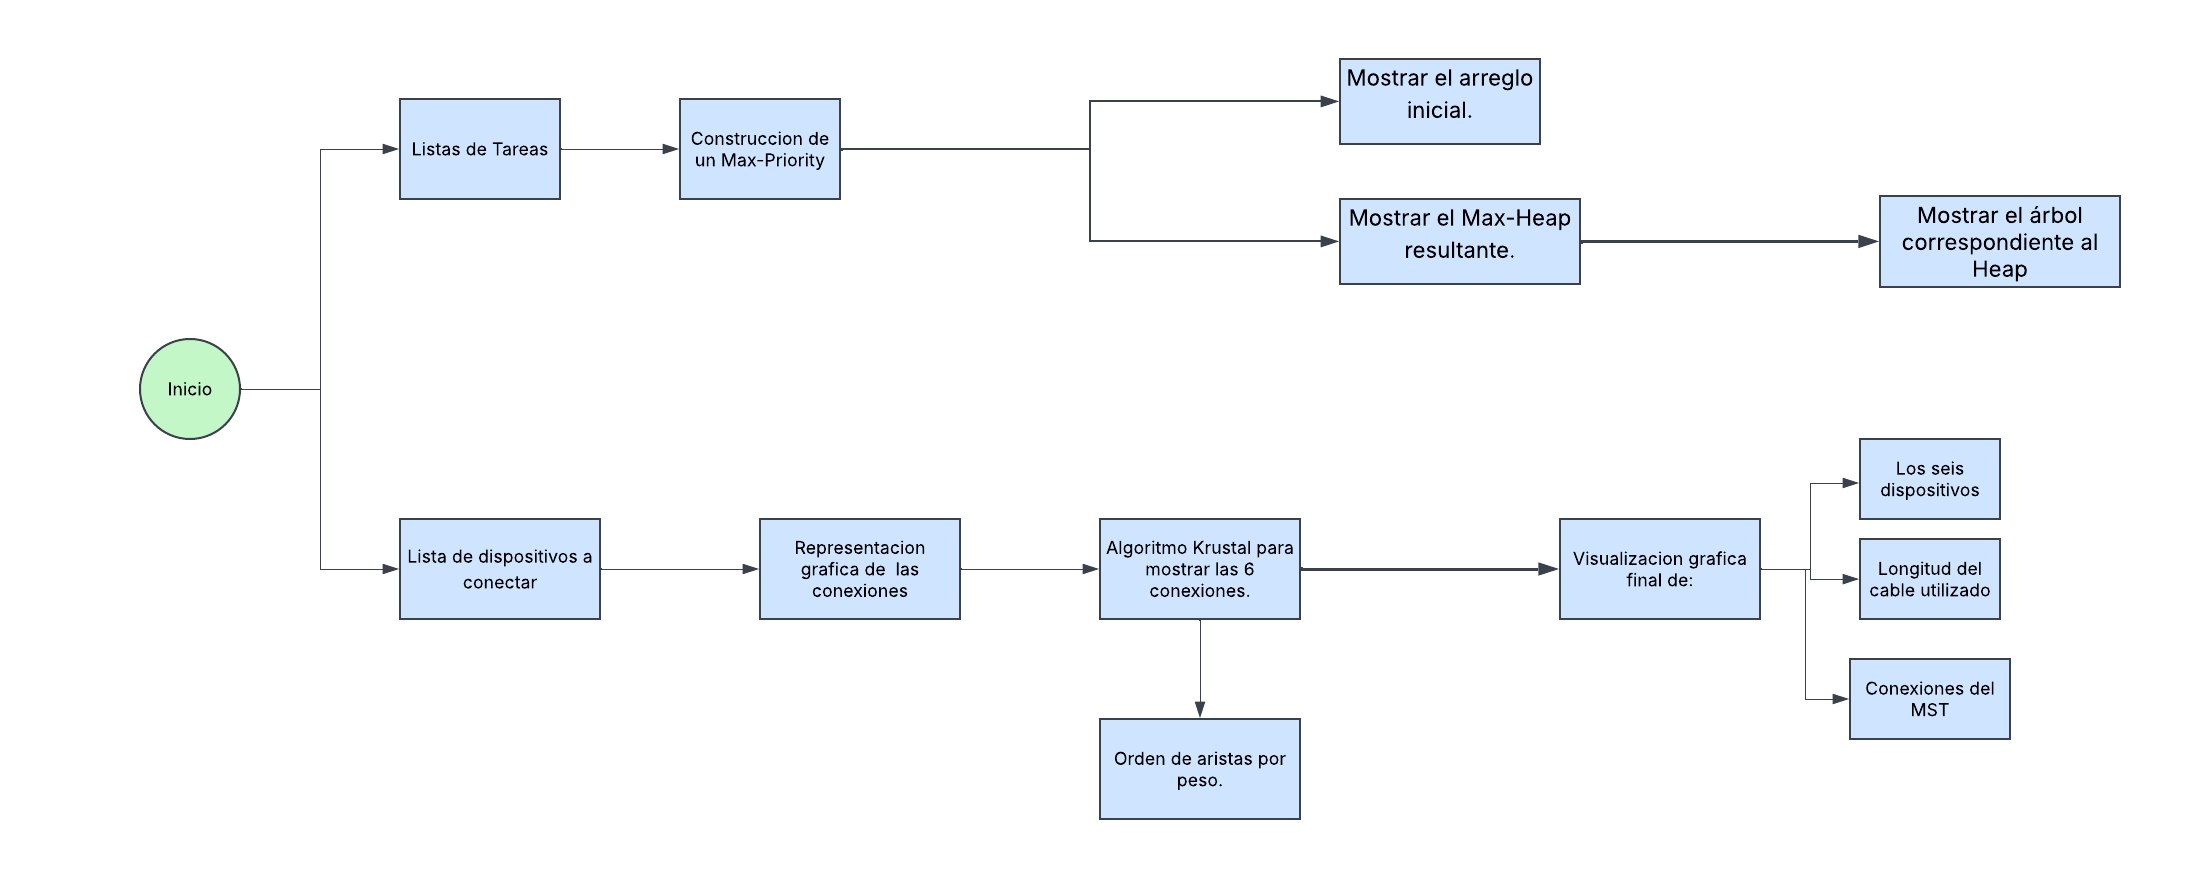


El diagrama de flujo muestra el incio del sistema dividiendose en dos, dependiendo de si se manejan tareas o dispositivos, muestra ademas cada uno de los requerimientos del sistema.

### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
- Función T[n]
- Mejor y peor caso con gráfica


## 6) Código funcional **[15 pts]**


In [ ]:
import math
from itertools import combinations
import matplotlib.pyplot as plt


#1

def maxh(heap, i, n):
    while True:
        may = i
        for hijo in (2 * i + 1, 2 * i + 2):
            if hijo < n and heap[hijo][2] > heap[may][2]:
                may = hijo
        if may == i:
            return
        heap[i], heap[may] = heap[may], heap[i]
        i = may


def conmaxh(heap):
    for i in range(len(heap) // 2 - 1, -1, -1):
        maxh(heap, i, len(heap))


def mostrar_heap(heap):
    print(heap)
    inicio, niv = 0, 0
    while inicio < len(heap):
        fin = inicio + 2 ** niv
        print("niv", niv, ":", heap[inicio:fin])
        inicio, niv = fin, niv + 1


#2
# Extraer el maximo e insertar una tarea nueva
def extract_max(heap):
    if not heap:
        return None
    heap[0], heap[-1] = heap[-1], heap[0]
    may = heap.pop()
    maxh(heap, 0, len(heap))
    return may


def insertar(heap, tarea):
    heap.append(tarea)
    i = len(heap) - 1
    while i > 0 and heap[i][2] > heap[(i - 1) // 2][2]:
        pad = (i - 1) // 2
        heap[i], heap[pad] = heap[pad], heap[i]
        i = pad


#3

def crear_aris(dispo):
    aris = []
    for a, b in combinations(dispo, 2):
        peso = math.dist(a[1:], b[1:])
        aris.append((peso, a[0], b[0]))
    return aris




#4

def buscar(grandes, x):
    while grandes[x] != x:
        grandes[x] = grandes[grandes[x]]  
        x = grandes[x]
    return x


def kruskal(dispo, aris):
    grandes = {d[0]: d[0] for d in dispo}
    mst, total = [], 0

    for peso, origen, destino in sorted(aris):
        r1, r2 = buscar(grandes, origen), buscar(grandes, destino)
        if r1 != r2:
            grandes[r1] = r2
            mst.append((peso, origen, destino))
            total += peso
            if len(mst) == len(dispo) - 1:
                break

    return mst, total


def imprimir_aris(aris):
    for peso, origen, destino in aris:
        print(origen, "-", destino, ":", round(peso, 2))


def main():
    tareas = [
        ("T01", "Configurar servidor", 6),
        ("T02", "Reparar sensor", 10),
        ("T03", "Actualizar software", 4),
        ("T04", "Revisar camara", 8),
        ("T05", "Generar respaldo", 3),
        ("T06", "Configurar alarma", 7),
    ]

    print("#1")
    print("Arreglo inicial:", tareas)
    conmaxh(tareas)
    print("Max-Heap:")
    mostrar_heap(tareas)

    print("#2")
    for i in range(2):
        print("Tarea procesada:", extract_max(tareas))
        print("Heap resultante:")
        mostrar_heap(tareas)

    insertar(tareas, ("T07", "Falla en sistema contra incendios", 12))
    print("Heap despues de insertar T07:")
    mostrar_heap(tareas)

    print("#3")
    dispo = [
        ("A", 2, 2), ("B", 7, 3), ("C", 4, 7),
        ("D", 10, 8), ("E", 13, 3), ("F", 15, 7),
    ]
    graficar(dispo, "Posicion de los dispo")
    aris = crear_aris(dispo)
    print("Distancias entre dispo:")
    imprimir_aris(aris)

    print("#4")
    mst, total = kruskal(dispo, aris)
    print("Conexiones seleccionadas:")
    imprimir_aris(mst)
    print("Longitud total de cable:", round(total, 2))

    print("#5")
    
    graficar(dispo, "Arbol de expansion minima - Total: " + str(round(total, 2)), mst)


    main()

## 7) Tests aplicados **[15 pts]**

In [ ]:
# (Opcional) Ejemplo de asserts (ajusta a tu código):
# assert funcion(0) == 0
# assert funcion(1) == 1
# assert funcion(6) == 8
